# MeterTrace — Notebook 07: Model Explainability

**Project:** MeterTrace: Electricity Theft Detection and Consumption Anomaly Analysis
**Phase:** 7 of 8

## Purpose
Notebook 06 found that the **Random Forest** on the 11 engineered features is our best model (test ROC-AUC
0.7702, Precision@100 0.68). This notebook explains **how it reaches its scores**:

1. **Global view:** which features the forest relies on most (built-in feature importance and SHAP).
2. **Local view:** why three individual test customers received the score they did.
3. **Limitations:** what these explanations can and cannot tell us.

## Rules followed in this notebook
- Notebook 06 holds the **final** test results. Nothing here retrains a model, changes a threshold or
  revises those results. We only **load** the saved Random Forest, the saved features, the frozen threshold
  and the saved test scores.
- SHAP's `TreeExplainer` reads the structure of the already-trained trees. It is **not fitted** to any data.
- `CONS_NO` and `FLAG` are never model inputs. `FLAG` is used only to describe the example customers.
- Explanations describe **what the model does**, not why a customer did or did not steal electricity.

## Outputs
- `outputs/figures/07_rf_feature_importance.png`, `07_shap_summary.png`,
  `07_local_explanations.png`, `07_example_customer_histories.png`
- `outputs/results/07_feature_importance.csv`, `07_local_explanations.csv`

## 0. Setup

In [1]:
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
import shap

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---- Paths (work from the notebooks/ folder or from the project root) ----
if Path.cwd().name == "notebooks":
    PROJECT_ROOT = Path.cwd().parent
else:
    PROJECT_ROOT = Path.cwd()

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"

features_metadata = json.loads((PROCESSED_DIR / "features_metadata.json").read_text())
FEATURE_COLUMNS = features_metadata["feature_columns"]
LABEL_COLUMN = features_metadata["label_column"]
MODEL_NAME = "Random Forest"

SHAP_SAMPLE_SIZE = 1000          # test customers used for the global SHAP plot (runtime, see Section 3)

TOWARDS_THEFT_COLOR = "#eb6834"   # pushes the score up (towards theft)
TOWARDS_NORMAL_COLOR = "#2a78d6"  # pushes the score down (towards normal)
NEUTRAL_COLOR = "#52514e"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("scikit-learn", sklearn.__version__, "| shap", shap.__version__)

scikit-learn 1.9.1 | shap 0.54.1


## 1. Load the saved model, features, frozen threshold and final test scores

In [3]:
random_forest = joblib.load(MODEL_DIR / "random_forest.joblib")
frozen_threshold = pd.read_csv(RESULTS_DIR / "06_validation_thresholds.csv", index_col="Model").loc[MODEL_NAME, "Threshold"]
test_scores = pd.read_csv(RESULTS_DIR / "06_test_scores.csv", index_col="CONS_NO")

train_features = pd.read_parquet(PROCESSED_DIR / "features_train.parquet")
test_features = pd.read_parquet(PROCESSED_DIR / "features_test.parquet")
X_test = test_features[FEATURE_COLUMNS]

print("Random Forest classes:", random_forest.classes_, "-> column 1 = theft (FLAG = 1)")
print("Frozen Random Forest threshold from Notebook 06:", frozen_threshold)
print("Test customers:", len(X_test))

Random Forest classes: [0 1] -> column 1 = theft (FLAG = 1)
Frozen Random Forest threshold from Notebook 06: 0.25
Test customers: 6356


### Consistency checks
The explanations must describe **exactly** the predictions reported in Notebook 06.

In [4]:
recomputed_probability = random_forest.predict_proba(X_test)[:, 1]

print("Test features and Notebook 06 scores in the same customer order:", bool((test_features.index == test_scores.index).all()))
print("Labels identical:", bool((test_features[LABEL_COLUMN] == test_scores[LABEL_COLUMN]).all()))
print("Saved model reproduces the Notebook 06 Random Forest scores:",
      np.allclose(recomputed_probability, test_scores[MODEL_NAME]))
print("Flags equal 'score >= frozen threshold':",
      bool(((test_scores[MODEL_NAME] >= frozen_threshold) == test_scores[f"{MODEL_NAME} flagged"]).all()))

Test features and Notebook 06 scores in the same customer order: True
Labels identical: True
Saved model reproduces the Notebook 06 Random Forest scores: True
Flags equal 'score >= frozen threshold': True


## 2. Global feature importance (built into the Random Forest)
Each tree splits customers on one feature at a time. The **impurity-based importance** of a feature is how
much, on average over all splits and trees, splitting on that feature made the groups "purer" (more clearly
theft or normal). The importances add up to 1. They were computed **during training** on training
customers, so nothing new is fitted here.

Two cautions:
- This importance tends to **favour features with many distinct values** (continuous kWh amounts) over
  features with few values.
- When two features carry the **same information**, the forest may use either, so their importance is
  **shared** between them.

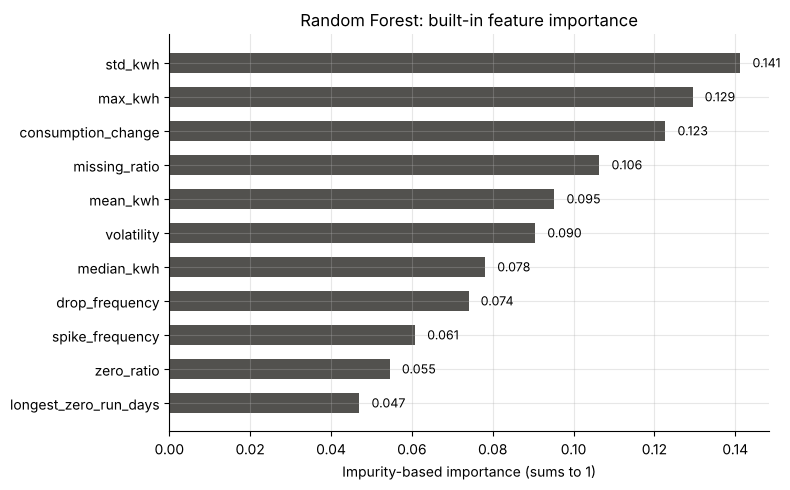

,importance
std_kwh,0.1413
max_kwh,0.1294
consumption_change,0.1227
missing_ratio,0.1064
mean_kwh,0.0952
volatility,0.0905
median_kwh,0.0781
drop_frequency,0.0740
spike_frequency,0.0608
zero_ratio,0.0545


In [5]:
feature_importance = pd.Series(random_forest.feature_importances_, index=FEATURE_COLUMNS, name="importance")
feature_importance = feature_importance.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(feature_importance.index, feature_importance.values, color=NEUTRAL_COLOR, height=0.6)
for row, value in enumerate(feature_importance.values):
    ax.text(value + 0.003, row, f"{value:.3f}", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Impurity-based importance (sums to 1)")
ax.set_title("Random Forest: built-in feature importance")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "07_rf_feature_importance.png", dpi=120)
plt.show()

feature_importance.round(4).to_frame()

**What we see: the five most important features**

| Rank | Feature | Importance | Meaning in electricity terms |
|---|---|---|---|
| 1 | `std_kwh` | 0.1413 | How much the customer's daily consumption **varies** around its average |
| 2 | `max_kwh` | 0.1294 | The customer's **highest** daily reading (after the Notebook 02 cap) |
| 3 | `consumption_change` | 0.1227 | Whether consumption **rose or fell** between the first and second half of the customer's history |
| 4 | `missing_ratio` | 0.1064 | The share of days with **no meter reading** |
| 5 | `mean_kwh` | 0.0952 | The customer's **average** daily consumption |

- **The forest leans on level and variability.** The size and variability of consumption (`std_kwh`,
  `max_kwh`, `mean_kwh`), the change over time, and missing readings matter most. Zero-reading features
  matter least.
- **Importance is not causation.** These numbers say which features the trees *used* to separate the
  labels in the training data. They do **not** say that variable consumption *causes* theft, or that
  reducing it would make a customer honest. Missing readings, for example, could reflect meter
  installation dates or how the labels were collected.

## 3. SHAP explanations
**SHAP** (SHapley Additive exPlanations) splits one prediction into **contributions from each feature**:

$$\text{predicted theft probability} = \text{base value} + \sum_{\text{features}} \text{SHAP value of the feature}$$

- A **positive** SHAP value pushes this customer's theft probability **up**.
- A **negative** SHAP value pushes it **down**.
- The **base value** is the model's average output. Our forest was trained with `class_weight="balanced_subsample"`,
  which makes both classes count equally, so its base value is **0.5**, not the 8.5% theft share.

`TreeExplainer` computes exact SHAP values from the trees themselves.

### Runtime and sample
Our forest has 100 fully grown trees with thousands of leaves each, so SHAP takes roughly 0.1 s per customer
on a CPU (about 10 minutes for all 6,356 test customers). For the **global** plot we therefore use a
**random sample of 1,000 test customers** (fixed seed). The three individual explanations in Section 4 are
computed for exactly those customers.

In [6]:
random_generator = np.random.default_rng(RANDOM_STATE)
sample_positions = np.sort(random_generator.choice(len(X_test), size=SHAP_SAMPLE_SIZE, replace=False))
X_shap_sample = X_test.iloc[sample_positions]
print("SHAP sample:", X_shap_sample.shape, "| theft-labelled in sample:", int(test_features[LABEL_COLUMN].iloc[sample_positions].sum()))

tree_explainer = shap.TreeExplainer(random_forest)

start_time = time.perf_counter()
sample_shap_values = tree_explainer.shap_values(X_shap_sample)
shap_seconds = time.perf_counter() - start_time
print(f"SHAP computation time: {shap_seconds:.1f} s for {SHAP_SAMPLE_SIZE} customers")

SHAP sample: (1000, 11) | theft-labelled in sample: 91


SHAP computation time: 85.7 s for 1000 customers


### Checking the output format and the class orientation
For a two-class model, this SHAP version returns one array of shape
**(customers, features, classes)**. The last axis follows `random_forest.classes_ = [0, 1]`, so index **1**
holds the contributions to the **theft** probability. We check three things:
1. the shape,
2. that base value + contributions reproduces the model's theft probability exactly, and
3. that the normal-class contributions are simply the theft-class contributions with the opposite sign.

In [7]:
sample_shap_array = np.asarray(sample_shap_values)
THEFT_CLASS_INDEX = int(np.where(random_forest.classes_ == 1)[0][0])
theft_base_value = float(np.asarray(tree_explainer.expected_value)[THEFT_CLASS_INDEX])
theft_shap = sample_shap_array[:, :, THEFT_CLASS_INDEX]

reconstructed = theft_base_value + theft_shap.sum(axis=1)
model_probability = random_forest.predict_proba(X_shap_sample)[:, THEFT_CLASS_INDEX]

print("SHAP array shape (customers, features, classes):", sample_shap_array.shape)
print("Theft class index:", THEFT_CLASS_INDEX, "| base value for theft:", round(theft_base_value, 4))
print("Base value + SHAP values = predicted theft probability:", np.allclose(reconstructed, model_probability, atol=1e-6))
print("Normal-class SHAP = - theft-class SHAP:", np.allclose(sample_shap_array[:, :, 1 - THEFT_CLASS_INDEX], -theft_shap, atol=1e-9))

SHAP array shape (customers, features, classes): (1000, 11, 2)
Theft class index: 1 | base value for theft: 0.5
Base value + SHAP values = predicted theft probability: True
Normal-class SHAP = - theft-class SHAP: True


### Global SHAP summary (1,000 test customers)
Each dot is one customer.

| Element | Meaning |
|---|---|
| Horizontal position | That feature's contribution to the customer's theft probability |
| Colour | The feature's value (red = high, blue = low) |
| Row order | Features sorted by average absolute contribution |

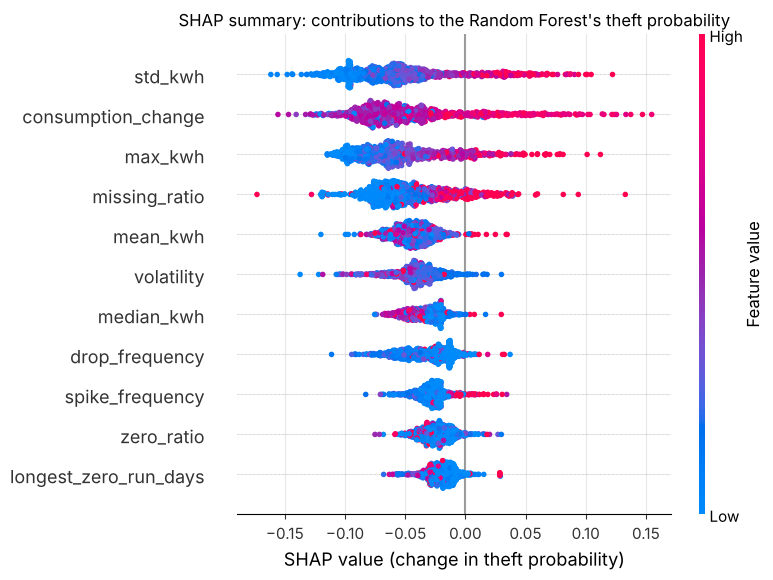

In [8]:
shap.summary_plot(theft_shap, X_shap_sample, show=False, rng=np.random.default_rng(RANDOM_STATE))
plt.title("SHAP summary: contributions to the Random Forest's theft probability")
plt.xlabel("SHAP value (change in theft probability)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "07_shap_summary.png", dpi=120)
plt.show()

In [9]:
mean_absolute_shap = pd.Series(np.abs(theft_shap).mean(axis=0), index=FEATURE_COLUMNS)

importance_comparison = pd.DataFrame({
    "Impurity importance": feature_importance,
    "Impurity rank": feature_importance.rank(ascending=False).astype(int),
    "Mean |SHAP| (1,000 test customers)": mean_absolute_shap,
    "SHAP rank": mean_absolute_shap.rank(ascending=False).astype(int),
}).sort_values("SHAP rank")
importance_comparison.round(4).to_csv(RESULTS_DIR / "07_feature_importance.csv")
importance_comparison.round(4)

,Impurity importance,Impurity rank,"Mean |SHAP| (1,000 test customers)",SHAP rank
std_kwh,0.1413,1,0.0625,1
consumption_change,0.1227,3,0.0582,2
max_kwh,0.1294,2,0.0568,3
missing_ratio,0.1064,4,0.0481,4
mean_kwh,0.0952,5,0.0431,5
volatility,0.0905,6,0.0408,6
median_kwh,0.0781,7,0.0342,7
drop_frequency,0.0740,8,0.0331,8
spike_frequency,0.0608,9,0.0283,9
zero_ratio,0.0545,10,0.0244,10


**What we see.**
- **Runtime and checks:** SHAP took about 80–85 s for 1,000 test customers on the CPU. All three format
  checks pass: the shape is (1000, 11, 2), base value + contributions equals each predicted theft
  probability, and the normal class is the mirror image of the theft class.
- **Same top five as the built-in importance:** the mean |SHAP| ranking has the same top five features,
  with `consumption_change` and `max_kwh` swapping places.
- **Reading the colours in the summary plot:**
  - **High `std_kwh` and high `max_kwh`** (red dots) sit on the **right**: large, variable consumption
    pushes the theft probability **up**.
  - **High `consumption_change`** (consumption that *rose* over time) pushes **up**; falling consumption
    tends to push **down**. Many people would expect theft to show up as *falling* recorded consumption,
    but in this dataset the theft label goes with rising consumption (as Notebooks 01 and 03 also showed).
  - **High `missing_ratio`** mostly pushes **up**, though not for every customer.
- **Why most dots are negative:** the base value is 0.5 (because of the balanced class weights), while most
  customers are normal and receive scores well below 0.5. So for most customers, most features push the
  probability **down** from 0.5.

## 4. Three individual customers
We pick one customer from each of three groups of the **held-out test set**, using the Random Forest's
**frozen** Notebook 06 threshold:

| Group | Meaning |
|---|---|
| **Correctly flagged theft** | label = theft, score ≥ threshold (true positive) |
| **False alarm** | label = normal, score ≥ threshold (false positive) |
| **Missed theft** | label = theft, score < threshold (false negative) |

**Selection rule (fixed in advance, not chosen to look good):** inside each group, take the customer whose
Random Forest score is **closest to the group's median score**, so it is a *typical* member of its group,
not an extreme one. Random Forest scores come in steps of 0.01, so several customers can be equally close;
then the first one in the saved test order is used. These three customers illustrate how the model reasons. They are **not
representative of every customer**.

In [10]:
rf_score = test_scores[MODEL_NAME]
rf_flagged = test_scores[f"{MODEL_NAME} flagged"]
label = test_scores[LABEL_COLUMN]

example_groups = {
    "Correctly flagged theft": rf_flagged & (label == 1),
    "False alarm (normal flagged)": rf_flagged & (label == 0),
    "Missed theft": ~rf_flagged & (label == 1),
}

example_ids = {}
for group_name, in_group in example_groups.items():
    group_scores = rf_score[in_group]
    distance_to_median = (group_scores - group_scores.median()).abs()
    example_ids[group_name] = distance_to_median.idxmin()
    print(f"{group_name:30s} group size {int(in_group.sum()):5d} | median score {group_scores.median():.3f} "
          f"| chosen customer {example_ids[group_name][:12]}… score {rf_score[example_ids[group_name]]:.3f}")

Correctly flagged theft        group size   177 | median score 0.380 | chosen customer 6BAED28FA2C7… score 0.380
False alarm (normal flagged)   group size   240 | median score 0.310 | chosen customer 7169453F4DC3… score 0.310
Missed theft                   group size   365 | median score 0.090 | chosen customer 3458D6B72AFE… score 0.090


### Feature values of the three customers
Each value is shown next to the **median training customer**, so "high" and "low" have a reference point.
(The training median is a description of the training data; nothing is fitted.)

In [11]:
example_names = list(example_ids.keys())
example_customer_ids = [example_ids[name] for name in example_names]

feature_values_table = X_test.loc[example_customer_ids].T
feature_values_table.columns = example_names
feature_values_table.insert(0, "Median training customer", train_features[FEATURE_COLUMNS].median())
feature_values_table.round(4)

,Median training customer,Correctly flagged theft,False alarm (normal flagged),Missed theft
mean_kwh,5.6619,67.9026,97.6453,8.4827
median_kwh,4.7600,63.0700,108.1950,9.5900
std_kwh,3.2566,42.5422,50.2352,6.4558
max_kwh,22.8900,227.4300,202.4900,31.8900
zero_ratio,0.0070,0.0166,0.0255,0.1518
missing_ratio,0.1094,0.7086,0.1268,0.0048
volatility,0.2384,0.2073,0.1541,0.2737
longest_zero_run_days,2.0000,5.0000,21.0000,19.0000
spike_frequency,0.0020,0.0202,0.0103,0.0242
drop_frequency,0.0133,0.0404,0.0400,0.1132


### Local SHAP explanations
We compute SHAP values for these three customers and draw, for each, the contribution of every feature to its
theft probability. Orange bars push **towards theft**, blue bars push **towards normal**. The bars start from
the base value (0.5) and end at the customer's score.

In [12]:
example_shap_array = np.asarray(tree_explainer.shap_values(X_test.loc[example_customer_ids]))
example_theft_shap = pd.DataFrame(example_shap_array[:, :, THEFT_CLASS_INDEX], index=example_names, columns=FEATURE_COLUMNS).T

print("Check: base value + SHAP values = saved Notebook 06 score")
for name in example_names:
    print(f"  {name:30s} {theft_base_value + example_theft_shap[name].sum():.4f} vs {rf_score[example_ids[name]]:.4f}")

local_explanations = pd.DataFrame({
    "customer": [example_ids[name] for name in example_names for _ in FEATURE_COLUMNS],
    "group": [name for name in example_names for _ in FEATURE_COLUMNS],
    "feature": FEATURE_COLUMNS * len(example_names),
    "feature_value": [X_test.loc[example_ids[name], feature] for name in example_names for feature in FEATURE_COLUMNS],
    "shap_value_theft": [example_theft_shap.loc[feature, name] for name in example_names for feature in FEATURE_COLUMNS],
})
local_explanations.to_csv(RESULTS_DIR / "07_local_explanations.csv", index=False)
example_theft_shap.round(4)

Check: base value + SHAP values = saved Notebook 06 score
  Correctly flagged theft        0.3800 vs 0.3800
  False alarm (normal flagged)   0.3100 vs 0.3100
  Missed theft                   0.0900 vs 0.0900


,Correctly flagged theft,False alarm (normal flagged),Missed theft
mean_kwh,0.0123,-0.0072,-0.0347
median_kwh,-0.0103,-0.0322,-0.0319
std_kwh,0.0793,0.0719,-0.0399
max_kwh,0.0696,0.0370,-0.0600
zero_ratio,-0.0340,-0.0324,0.0070
missing_ratio,-0.0064,-0.0345,-0.0641
volatility,-0.0314,-0.0334,-0.0476
longest_zero_run_days,-0.0376,-0.0051,-0.0039
spike_frequency,-0.0479,-0.0430,-0.0028
drop_frequency,-0.0454,-0.0433,-0.0369


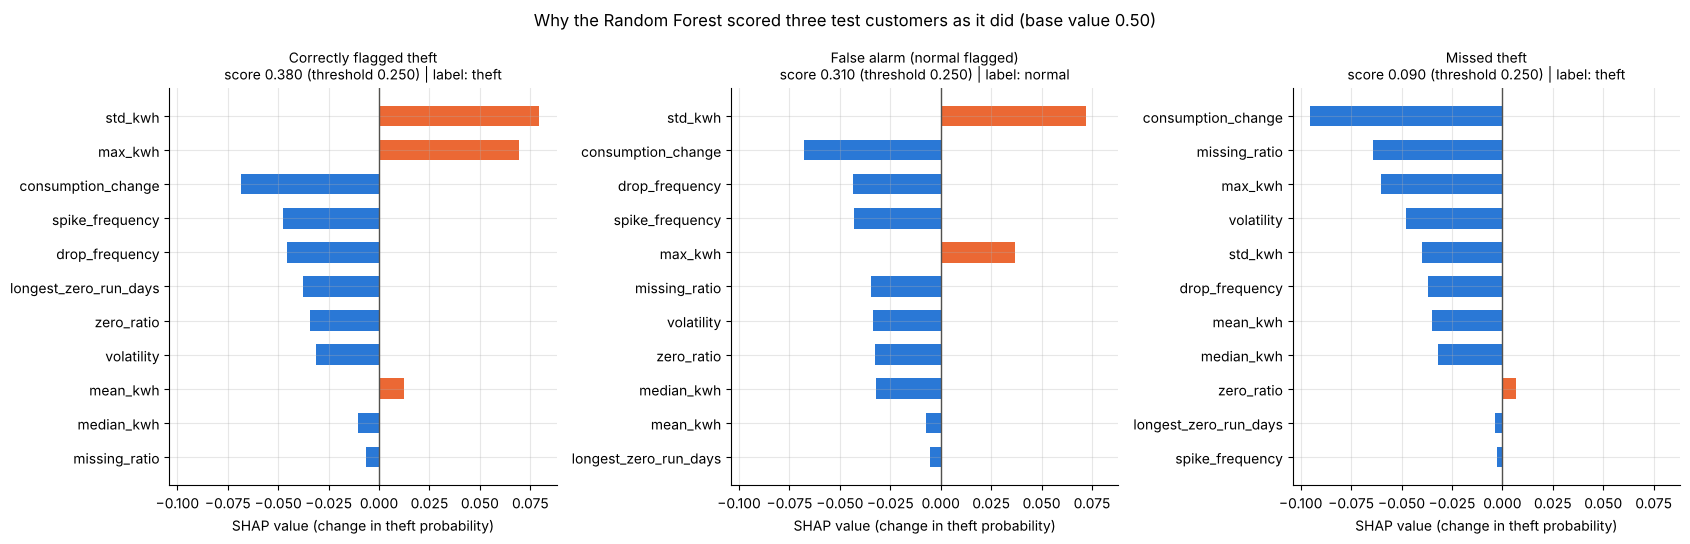

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharex=True)
for panel, name in zip(axes, example_names):
    contributions = example_theft_shap[name].sort_values(key=np.abs, ascending=True)
    colors = np.where(contributions.to_numpy() > 0, TOWARDS_THEFT_COLOR, TOWARDS_NORMAL_COLOR)
    panel.barh(contributions.index, contributions.to_numpy(), color=colors, height=0.6)
    panel.axvline(0, color=NEUTRAL_COLOR, linewidth=1)
    customer_id = example_ids[name]
    panel.set_title(f"{name}\nscore {rf_score[customer_id]:.3f} (threshold {frozen_threshold:.3f}) | "
                    f"label: {'theft' if label[customer_id] == 1 else 'normal'}", fontsize=10)
    panel.set_xlabel("SHAP value (change in theft probability)")
fig.suptitle(f"Why the Random Forest scored three test customers as it did (base value {theft_base_value:.2f})")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "07_local_explanations.png", dpi=120)
plt.show()

### The three customers' daily consumption
An investigator would look at the readings behind the features. These are the cleaned daily readings from
Notebook 02: capped, **not imputed**, so gaps are real missing days, and 3 Oct 2014 is blanked.

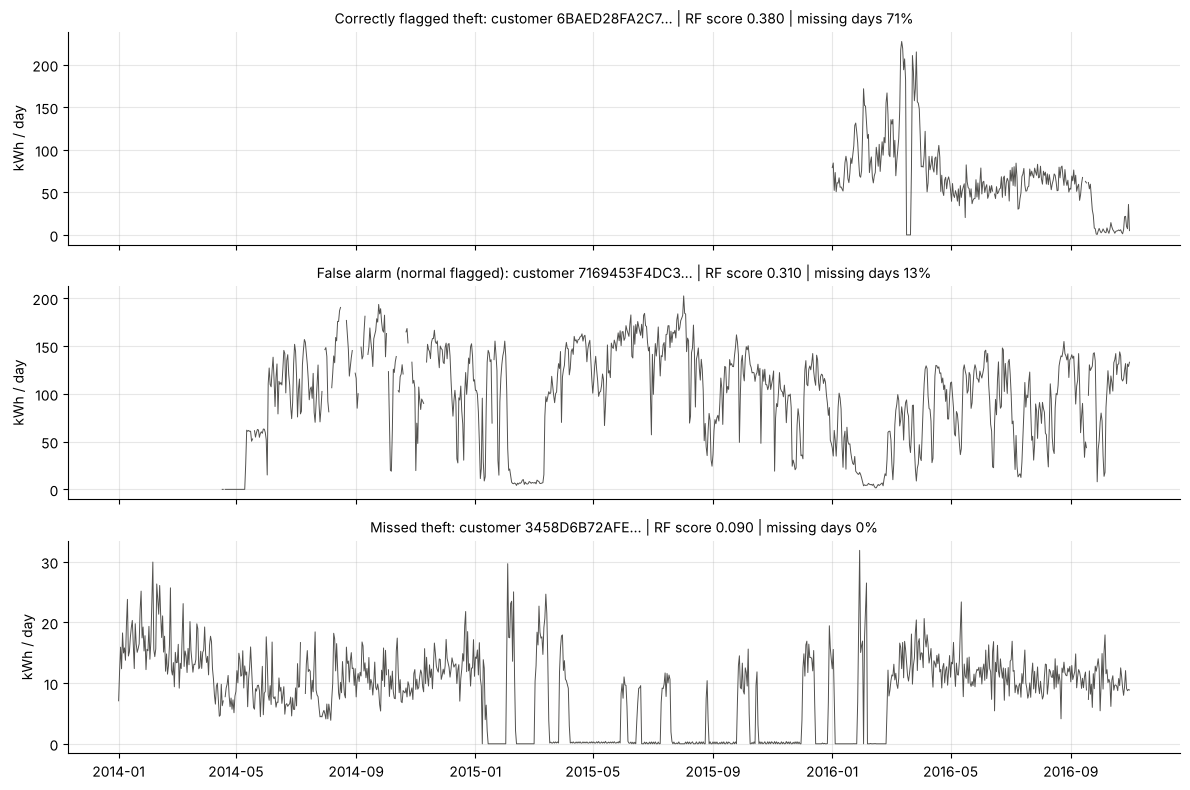

In [14]:
daily_clean = pd.read_parquet(PROCESSED_DIR / "daily_clean.parquet").loc[example_customer_ids]
daily_clean.columns = pd.to_datetime(daily_clean.columns)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for panel, name in zip(axes, example_names):
    customer_id = example_ids[name]
    panel.plot(daily_clean.columns, daily_clean.loc[customer_id], color=NEUTRAL_COLOR, linewidth=0.7)
    panel.set_ylabel("kWh / day")
    panel.set_title(f"{name}: customer {customer_id[:12]}… | RF score {rf_score[customer_id]:.3f} | "
                    f"missing days {X_test.loc[customer_id, 'missing_ratio']:.0%}", fontsize=10)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "07_example_customer_histories.png", dpi=120)
plt.show()

**What the three examples show.** They are *typical* members of their groups, chosen by the fixed rule
above, and are not representative of every customer.

**1. Correctly flagged theft** (score 0.380, threshold 0.250)
- **Profile:** a large consumer (68 kWh/day on average, against 5.7 for the median training customer). It
  reports only from January 2016 (71% of days missing).
- **Pushes up:** high variability (`std_kwh` +0.079) and a high maximum (`max_kwh` +0.070).
- **Pushes down:** most other features, especially `consumption_change` (−0.068). The customer's
  consumption **fell** sharply towards the end, and in this dataset falling consumption is associated with
  the *normal* label.
- **Net result:** the score still ends above the threshold.

**2. False alarm, a normal-labelled customer flagged** (score 0.310)
- **Profile:** an even larger consumer (98 kWh/day) with strong seasonal swings.
- **Pushes up:** exactly the same two features (`std_kwh` +0.072, `max_kwh` +0.037).
- **What it shows:** the model's most important signal, large and variable consumption, also fits big
  legitimate customers. This is a typical source of false alarms, and why every flag needs a human check.

**3. Missed theft, a theft-labelled customer not flagged** (score 0.090)
- **Profile:** ordinary consumption (8.5 kWh/day), almost no missing days, and consumption that fell
  between the two halves of its history. Almost every feature pushes **down**; the strongest are
  `consumption_change` (−0.095), `missing_ratio` (−0.064) and `max_kwh` (−0.060).
- **What the history shows:** a long stretch of **very low consumption through most of 2015**, followed by
  a return to normal levels. Our features capture this only partly:
  - `zero_ratio` counts only days of **exactly** 0 kWh, not near-zero readings;
  - `consumption_change` compares just two halves.
- **Takeaway:** this is a limitation of hand-made features. A pattern that an analyst would find suspicious
  can still receive a low score.

## 5. Limitations of these explanations
### 5a. Correlated features share credit
Some features carry almost the same information. Spearman correlations on **training** customers:

In [15]:
correlated_pairs = [("mean_kwh", "median_kwh"), ("zero_ratio", "longest_zero_run_days"), ("std_kwh", "max_kwh")]
correlation_rows = []
for first_feature, second_feature in correlated_pairs:
    correlation_rows.append({
        "Feature pair": f"{first_feature} / {second_feature}",
        "Spearman correlation (train)": train_features[first_feature].corr(train_features[second_feature], method="spearman"),
        "Mean |SHAP| of first": mean_absolute_shap[first_feature],
        "Mean |SHAP| of second": mean_absolute_shap[second_feature],
    })
pd.DataFrame(correlation_rows).round(3)

,Feature pair,Spearman correlation (train),Mean |SHAP| of first,Mean |SHAP| of second
0,mean_kwh / median_kwh,0.959,0.043,0.034
1,zero_ratio / longest_zero_run_days,0.982,0.024,0.020
2,std_kwh / max_kwh,0.949,0.062,0.057


### 5b. Contradictory labels and flagged customers
Notebook 02 found identical-history groups whose members carry **both** labels (all zero-consumption meters).
How many of them are in the test set, and how many did the Random Forest flag?

In [16]:
in_contradictory_group = test_scores["in_contradictory_group"]
print("Test customers in contradictory-label groups:", int(in_contradictory_group.sum()),
      "| theft-labelled among them:", int(label[in_contradictory_group].sum()))
print("Of these, flagged by the Random Forest:", int((in_contradictory_group & rf_flagged).sum()))
print("Their Random Forest scores (min / max):",
      round(rf_score[in_contradictory_group].min(), 3), "/", round(rf_score[in_contradictory_group].max(), 3))

Test customers in contradictory-label groups: 91 | theft-labelled among them: 3
Of these, flagged by the Random Forest: 0
Their Random Forest scores (min / max): 0.0 / 0.08


### What these explanations can and cannot tell us
1. **Correlated features share credit.**
   - `mean_kwh` and `median_kwh` (Spearman 0.959), `zero_ratio` and `longest_zero_run_days` (0.982), and
     `std_kwh` and `max_kwh` (0.949) carry almost the same information.
   - The forest uses either member of a pair, so their importance and SHAP values are **split** between
     them (for example, mean |SHAP| 0.043 vs 0.034 for mean/median).
   - Adding up the two members of a pair gives a better idea of how much that *kind* of information
     matters than either number on its own.
2. **SHAP explains the model, not reality.** A positive SHAP value means "this feature value pushed *this
   model's* score towards theft". It is not evidence that the customer stole electricity, and it does not
   say *why* consumption looks the way it does (a new appliance, a business, a faulty meter, or theft).
3. **Missing readings can mislead.**
   - `missing_ratio` is the fourth most important feature, but missing days can come from late meter
     installation (many meters only start in 2016) or communication faults, not only from tampering.
   - The correctly flagged example has 71% of days missing for exactly this reason. In its case the
     missingness hardly affected the score (−0.006).
4. **Labels are imperfect.**
   - The test set contains 91 customers in contradictory-label groups (identical zero-consumption
     histories, 3 labelled theft). The forest flagged **none** of them (all scores ≤ 0.08). For those
     3 theft labels, the readings themselves give no basis for a flag.
   - Labels are per customer, with no theft date, so we cannot tell *when* any theft happened.
5. **The examples are illustrations.** Three customers cannot represent 6,356. They were picked by a fixed
   "closest to the group median" rule so that they are typical, not dramatic.

## What We Learned
Key ideas to be able to explain in the viva:

1. **Global vs. local explanations.** Feature importance and the SHAP summary describe the model **overall**.
   The three waterfall-style bar charts explain **one customer at a time**. Both are needed: an inspector
   cares about the individual case, while a professor or analyst checks that the overall behaviour is
   sensible.
2. **Two importance methods agreed.** The Random Forest's built-in importance and the mean |SHAP| ranking
   share the same top five features: `std_kwh`, `max_kwh`, `consumption_change`, `missing_ratio` and
   `mean_kwh`. Agreement between methods makes the picture more trustworthy.
3. **How SHAP works.** Base value (0.5, because of balanced class weights) + the sum of all feature
   contributions = the customer's score. Positive values push towards theft, negative values towards
   normal. We checked this addition exactly.
4. **Handle the class axis carefully.** For a two-class model, SHAP 0.54 returns
   (customers, features, classes). We used index 1, which matches `classes_ = [0, 1]` = theft, and checked
   that the normal class is its exact mirror image.
5. **False alarms have explanations too.** The false-alarm example was flagged for the same reason as the
   correctly flagged one: large, variable consumption. That pattern is common among theft labels in this
   dataset, but it also fits big legitimate customers.
6. **Missed cases reveal feature limitations.** The missed theft customer had a long near-zero period that
   our features (exact zeros, half-vs-half change) captured only partly.
7. **Explanations are not proof.** Feature importance is not causation, SHAP describes the model and not
   the customer's behaviour, correlated features share credit, and labels are imperfect. A flag plus its
   explanation is a well-documented **lead** for a human investigator.
8. **The final results stayed untouched.** No model, threshold or test result from Notebook 06 was changed.
   SHAP's TreeExplainer only reads the trained trees.